<a href="https://colab.research.google.com/github/code-with-ayyan/mental-health-score-prediction/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(context='notebook',
    style="whitegrid",
    palette="viridis")

In [ ]:
df = pd.read_csv('data.csv')
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


# EDA & Cleaning side by side

In [ ]:
data = df.copy()

In [ ]:
data.shape

(5000, 13)

In [ ]:
data

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,18,Female,Other,High School,YouTube,Education,1.9,89,6.1,2.2,7.9,Low,7.9
4996,18,Female,Other,High School,YouTube,Education,6.6,216,2.3,1.8,6.0,Very High,4.7
4997,19,Female,India,Undergraduate,LinkedIn,Education,3.8,151,5.4,1.4,7.5,Medium,7.0
4998,18,Male,Other,High School,Instagram,Entertainment,3.8,119,4.0,1.5,6.4,Medium,6.7


In [ ]:
data.columns = data.columns.str.lower().str.replace(' ', '_')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      5000 non-null   int64  
 1   gender                   5000 non-null   object 
 2   country                  5000 non-null   object 
 3   academic_level           5000 non-null   object 
 4   most_used_platform       5000 non-null   object 
 5   purpose_of_use           5000 non-null   object 
 6   avg_daily_usage_hours    5000 non-null   float64
 7   daily_unlocks            5000 non-null   int64  
 8   study_hours              5000 non-null   float64
 9   physical_activity_hours  5000 non-null   float64
 10  sleep_hours_per_night    5000 non-null   float64
 11  stress_level             5000 non-null   object 
 12  mental_health_score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [ ]:
data.describe()

,age,avg_daily_usage_hours,daily_unlocks,study_hours,physical_activity_hours,sleep_hours_per_night,mental_health_score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [ ]:
data = data[data['physical_activity_hours'] >= 0]

In [ ]:
data.isnull().sum()

,0
age,0
gender,0
country,0
academic_level,0
most_used_platform,0
purpose_of_use,0
avg_daily_usage_hours,0
daily_unlocks,0
study_hours,0
physical_activity_hours,0


In [ ]:
data.duplicated().sum()

np.int64(2)

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4988 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      4988 non-null   int64  
 1   gender                   4988 non-null   object 
 2   country                  4988 non-null   object 
 3   academic_level           4988 non-null   object 
 4   most_used_platform       4988 non-null   object 
 5   purpose_of_use           4988 non-null   object 
 6   avg_daily_usage_hours    4988 non-null   float64
 7   daily_unlocks            4988 non-null   int64  
 8   study_hours              4988 non-null   float64
 9   physical_activity_hours  4988 non-null   float64
 10  sleep_hours_per_night    4988 non-null   float64
 11  stress_level             4988 non-null   object 
 12  mental_health_score      4988 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 545.6+ KB


In [ ]:
data.describe()

,age,avg_daily_usage_hours,daily_unlocks,study_hours,physical_activity_hours,sleep_hours_per_night,mental_health_score
count,4988.000000,4988.000000,4988.000000,4988.000000,4988.000000,4988.000000,4988.000000
mean,20.822374,5.074539,171.347835,3.010706,1.754671,6.636949,6.233841
std,1.737116,1.652778,42.827688,1.637380,0.663322,1.221215,1.278005
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


<Axes: >

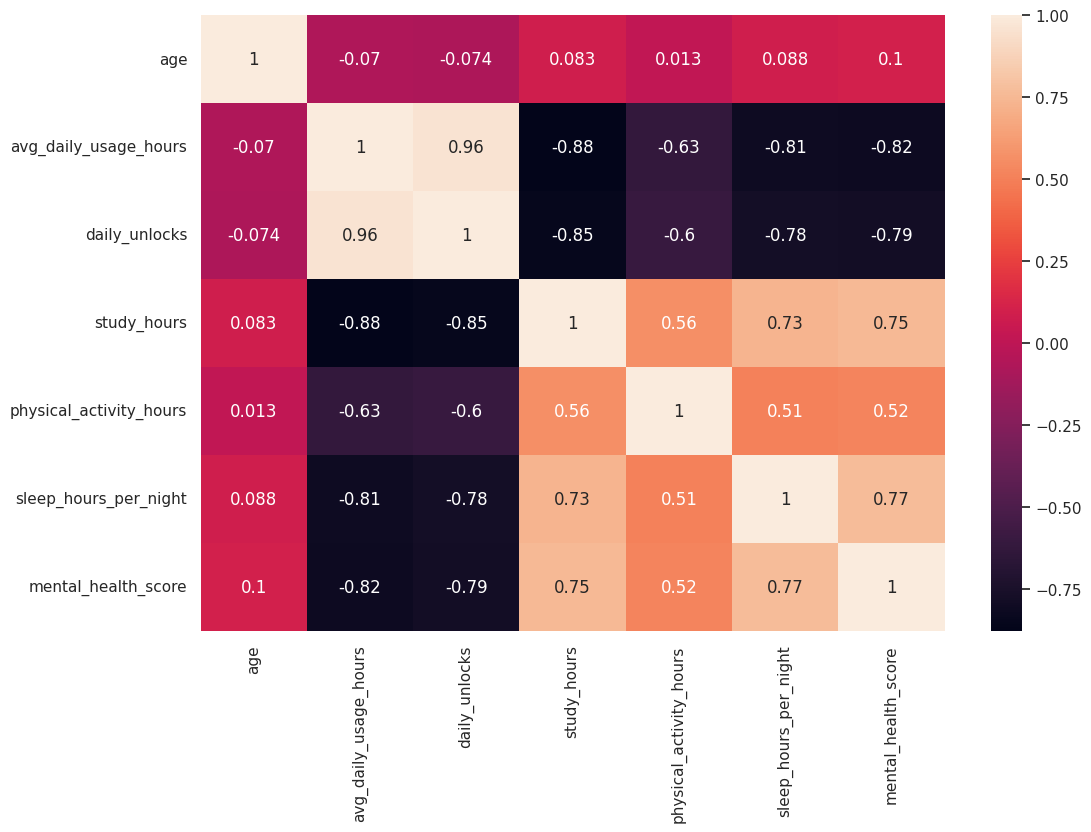

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(data= data.corr(numeric_only=True), annot=True)

**This shows the mental health score is highly correlated with almost all the features here**

**Let's have a Look at some relatonship in data**

<Axes: xlabel='mental_health_score', ylabel='Count'>

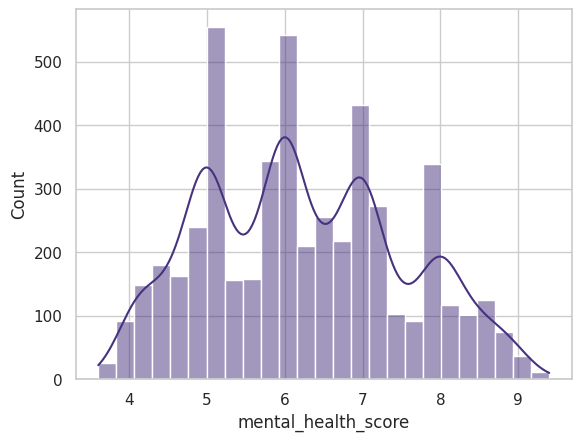

In [ ]:
sns.histplot(data['mental_health_score'], kde=True)

In [ ]:
data['stress_level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

<Axes: xlabel='stress_level', ylabel='mental_health_score'>

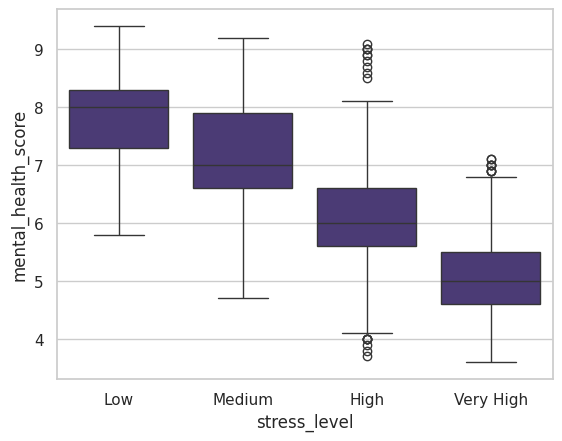

In [ ]:
order = ['Low', 'Medium', 'High', 'Very High']
data = data.set_index('stress_level').loc[order].reset_index()

sns.boxplot(x =data['stress_level'],y =data['mental_health_score'])

<Axes: xlabel='stress_level', ylabel='mental_health_score'>

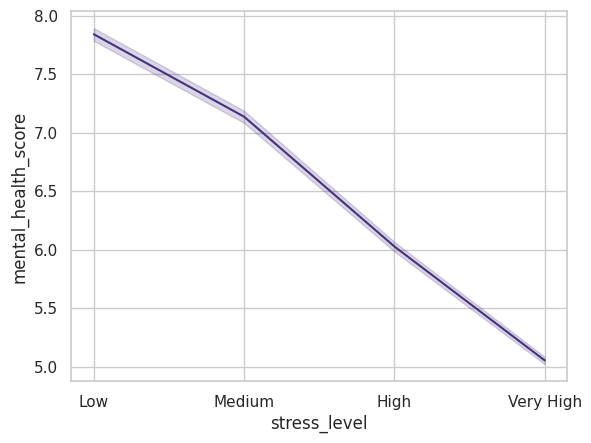

In [ ]:
sns.lineplot(x = data['stress_level'], y = data['mental_health_score'])

<Axes: xlabel='avg_daily_usage_hours', ylabel='mental_health_score'>

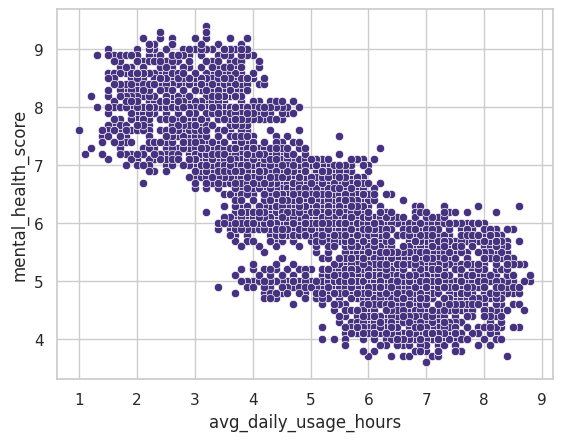

In [ ]:
sns.scatterplot(x=data['avg_daily_usage_hours'], y=data['mental_health_score'])

<Axes: xlabel='sleep_hours_per_night', ylabel='mental_health_score'>

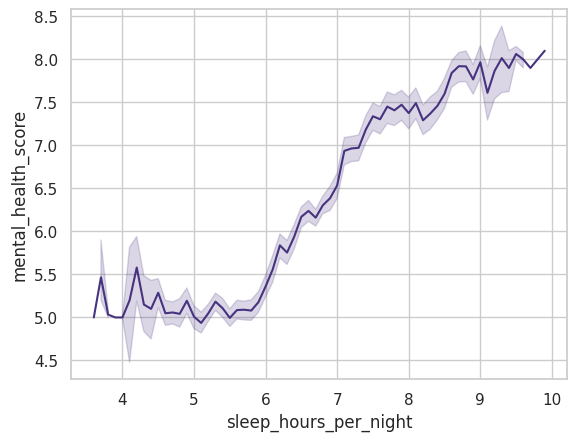

In [ ]:
sns.lineplot(x= data['sleep_hours_per_night'], y= data['mental_health_score'])

<Axes: xlabel='sleep_hours_per_night', ylabel='mental_health_score'>

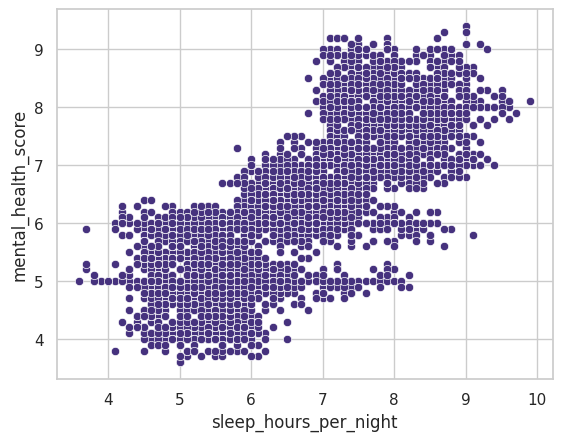

In [ ]:
sns.scatterplot(x= data['sleep_hours_per_night'], y= data['mental_health_score'])

**The graphs shows increasing sleep hour increase the mental health score and it decreases with the increase in avg daily mobile usage and stress level**

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [Text(0, 0, 'Instagram'),
  Text(1, 0, 'TikTok'),
  Text(2, 0, 'Facebook'),
  Text(3, 0, 'LinkedIn'),
  Text(4, 0, 'YouTube'),
  Text(5, 0, 'Twitter'),
  Text(6, 0, 'Snapchat'),
  Text(7, 0, 'WhatsApp'),
  Text(8, 0, 'LINE'),
  Text(9, 0, 'VKontakte'),
  Text(10, 0, 'KakaoTalk'),
  Text(11, 0, 'WeChat')])

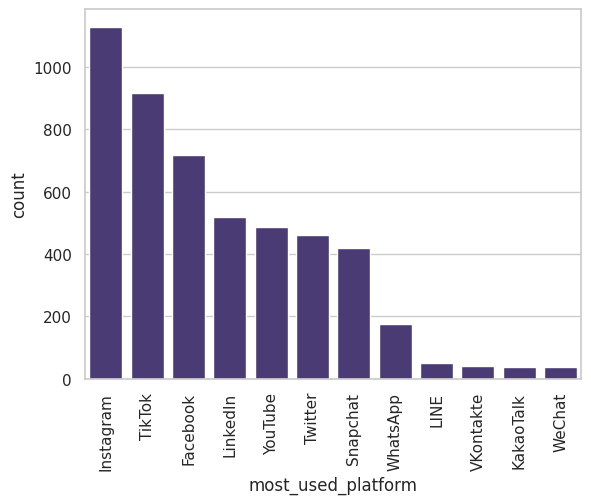

In [ ]:
order = data['most_used_platform'].value_counts().index
sns.countplot(x=data['most_used_platform'], order = order)
plt.xticks(rotation=90)

**Checking outliers**

In [ ]:
num_features = data.select_dtypes(include='number')

Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
outliers.sum()

,0
age,0
avg_daily_usage_hours,0
daily_unlocks,0
study_hours,2
physical_activity_hours,12
sleep_hours_per_night,0
mental_health_score,0


In [ ]:
lower_bound

,0
age,14.50
avg_daily_usage_hours,0.05
daily_unlocks,44.00
study_hours,-2.55
physical_activity_hours,-0.05
sleep_hours_per_night,2.75
mental_health_score,2.10


In [ ]:
upper_bound

,0
age,26.50
avg_daily_usage_hours,10.05
daily_unlocks,300.00
study_hours,8.25
physical_activity_hours,3.55
sleep_hours_per_night,10.35
mental_health_score,10.10


In [ ]:
data[data['physical_activity_hours'] > 3.55]['physical_activity_hours']

,physical_activity_hours
150,3.6
332,3.6
520,3.6
551,3.8
638,3.6
1098,3.6
1179,3.6
1291,3.6
1433,3.7
1573,4.1


In [ ]:
data[data['study_hours'] > 8.25]['study_hours']

,study_hours
384,8.3
597,8.3


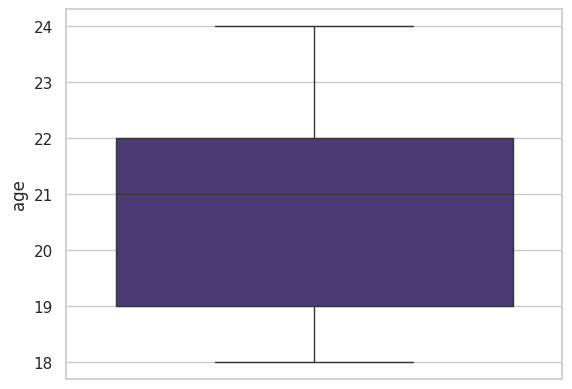

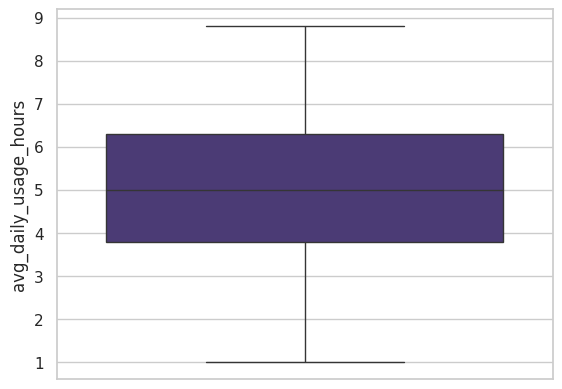

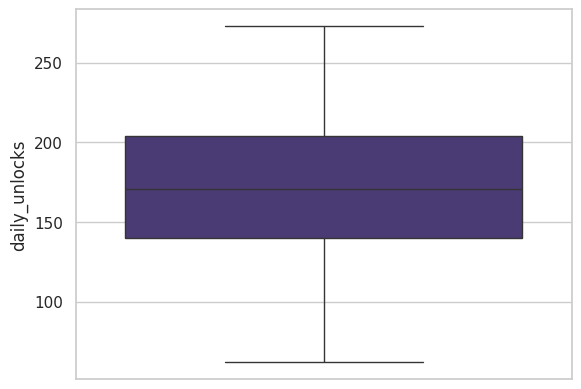

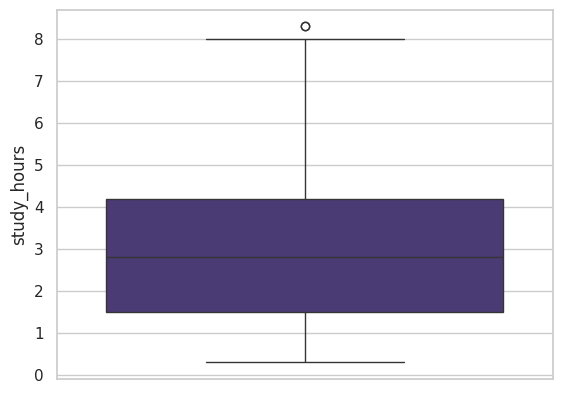

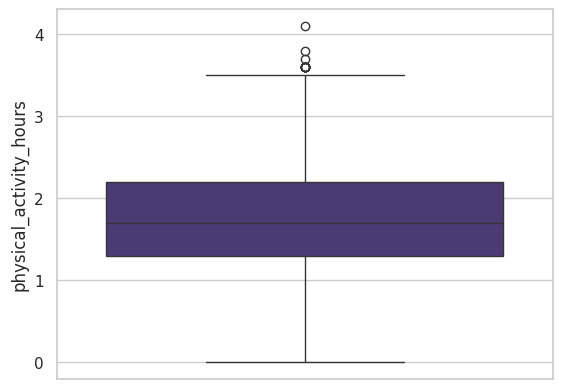

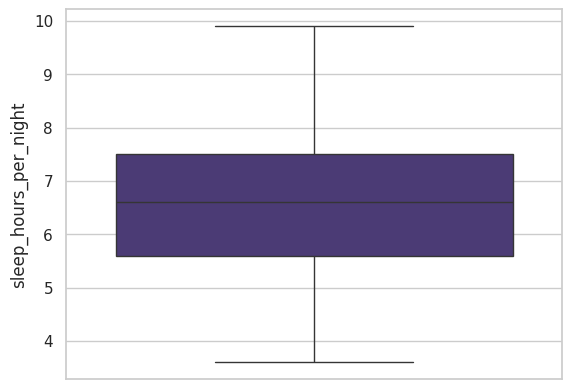

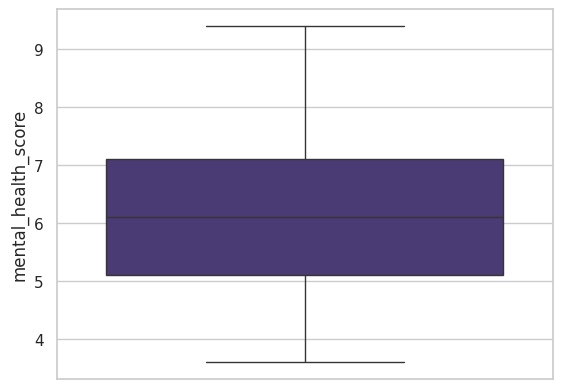

In [ ]:
cols = num_features.columns
for col in cols :
  sns.boxplot(data[col])
  plt.show()

**Checking Skewness in data**

In [ ]:
num_features.skew()

,0
age,0.153729
avg_daily_usage_hours,0.006916
daily_unlocks,0.004558
study_hours,0.433823
physical_activity_hours,0.075382
sleep_hours_per_night,0.121965
mental_health_score,0.205218


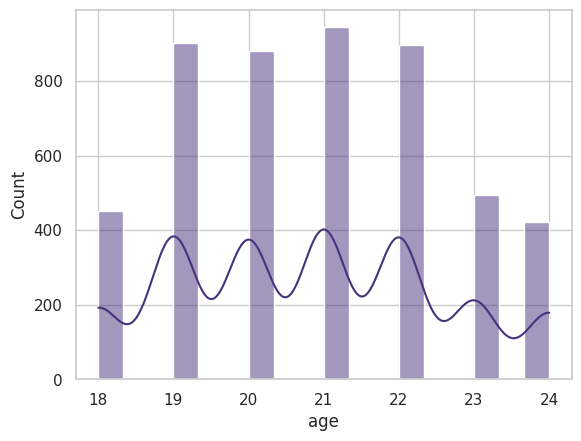

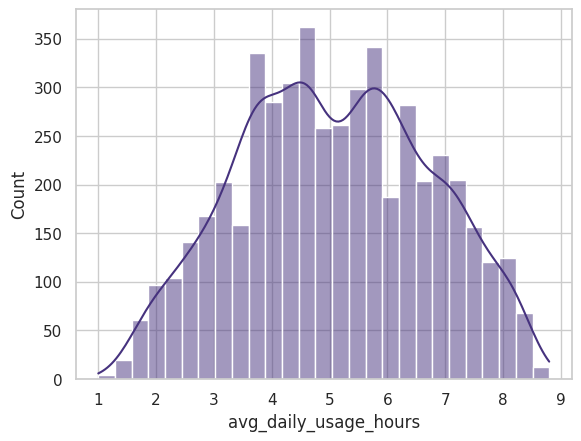

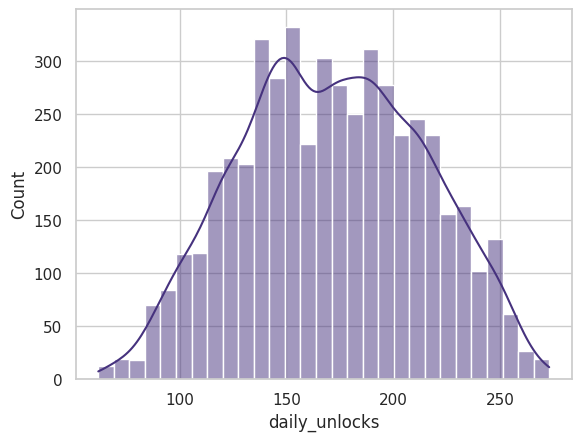

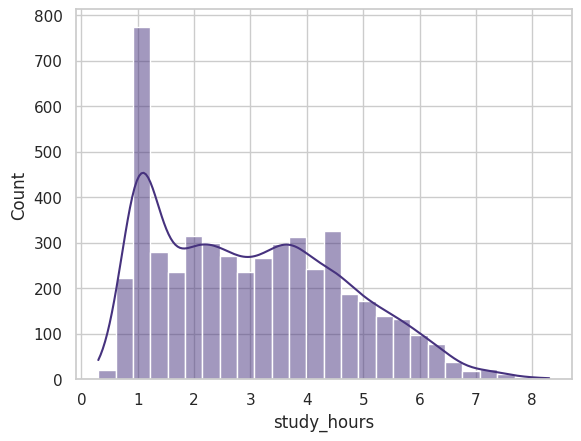

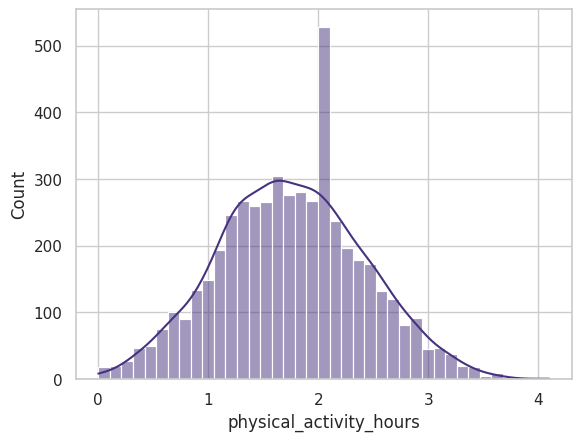

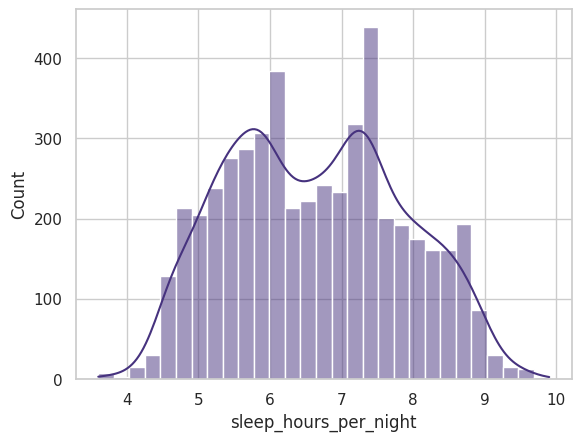

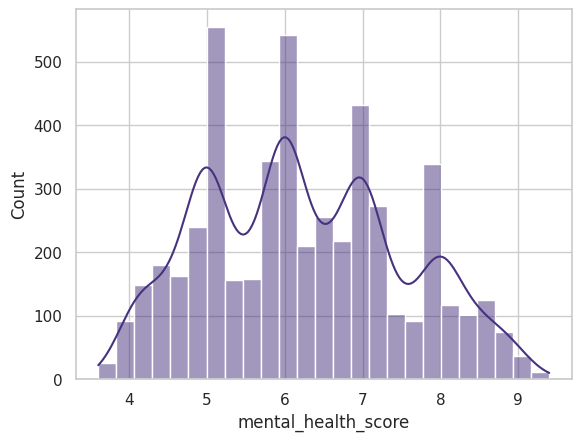

In [ ]:
for col in cols:
  sns.histplot(data[col], kde=True)
  plt.show()

**The graphs and nunmbers shows that our data is very good there are few outliers and skewness in data but it will be ok**

In [ ]:
data['country'].value_counts()

,count
country,
Other,1871
India,388
USA,353
Canada,230
Australia,198
...,...
Thailand,1
Ecuador,1
Armenia,1



*   Country has 111 unique values in this dataset — one-hot encoding that directly would add 110+ mostly-empty columns, which hurts the model far more than it helps.

*   Dropping Country entirely throws away real signal — a student's country genuinely correlates with things like internet access, culture, and sleep norms.

*   The fix: keep the top 15 most frequent countries as their own category, and bucket everything else into "other". We keep the signal that matters and lose the noise that doesn't.








In [ ]:
top_countries = data['country'].value_counts().index[:15].tolist()

In [ ]:
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [ ]:
data['grouped_country'] = data['country'].apply(group_countries)

In [ ]:
data['grouped_country'].value_counts()

,count
grouped_country,
Other,2832
India,388
USA,353
Canada,230
Australia,198
UK,185
Germany,136
Turkey,94
Mexico,94


# **Preprocessing**

In [ ]:
data.columns

Index(['stress_level', 'age', 'gender', 'country', 'academic_level',
       'most_used_platform', 'purpose_of_use', 'avg_daily_usage_hours',
       'daily_unlocks', 'study_hours', 'physical_activity_hours',
       'sleep_hours_per_night', 'mental_health_score', 'grouped_country'],
      dtype='object')

## **Preprocessing Strategy**



*   ['study_hours'] → As study hours was so much
right skewed so we will apply log transformation on it...


*   ['stress_level'] → As stress level has ranks ['Low', 'Medium','High','Very High] so we will apply ordinal encoder on it.

*   ["gender", "academic_level", "most_used_platform", "purpose_of_use", "grouped_country"] → These are categorical columns so I will perform ONeHotEncoding for them.

*   ["age", 'avg_daily_usage_hours', 'daily_unlocks','physical_activity_hours','sleep_hours_per_night'] → For these simple numerical columns I will apply StandardScalar on them.







In [ ]:
from sklearn.model_selection import train_test_split

skwewd_col         = ['study_hours']
ordinal_col        = ['stress_level']
cat_cols           = ["gender", "academic_level", "most_used_platform", "purpose_of_use", "grouped_country"]
num_cols           = ["age", 'avg_daily_usage_hours', 'daily_unlocks','physical_activity_hours','sleep_hours_per_night']


feature_col = skwewd_col + num_cols + ordinal_col + cat_cols
X = data[feature_col]
y = data['mental_health_score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

skew_transformer = Pipeline([
    ('log_transformer', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])

ordinal_transformer = Pipeline([
    ('ordinal_encoder', OrdinalEncoder())
])

onehot_transformer = Pipeline([
    ('onehot_encoder', OneHotEncoder(handle_unknown='ignore'))
])

num_transformer = Pipeline([
    ('scaler', StandardScaler())
])

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ('skew_transformer', skew_transformer, skwewd_col),
    ('ordinal_transformer', ordinal_transformer, ordinal_col),
    ('onehot_transformer', onehot_transformer, cat_cols),
    ('num_transformer', num_transformer, num_cols)
])

preprocessor

ColumnTransformer(transformers=[('skew_transformer',
                                 Pipeline(steps=[('log_transformer',
                                                  FunctionTransformer(func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['study_hours']),
                                ('ordinal_transformer',
                                 Pipeline(steps=[('ordinal_encoder',
                                                  OrdinalEncoder())]),
                                 ['stress_level']),
                                ('onehot_transformer',
                                 Pipeline(steps=[('onehot_encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'academic_level',
                                  'most_used_platform', 'purpose_of_use',
                                  'grouped_country']),
                                ('num_transformer',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['age', 'avg_daily_usage_hours',
                                  'daily_unlocks', 'physical_activity_hours',
                                  'sleep_hours_per_night'])])

# **Let's make a model evaluation helper function first**

In [ ]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

def evaluate_model(model_name, model, X_test, y_test):

  y_pred = model.predict(X_test)


  n = X_test.shape[0]
  p = X_test.shape[1]


  r2             = r2_score(y_test, y_pred)
  adjusted_r2    = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
  rmse           = root_mean_squared_error(y_test, y_pred)
  mae            = mean_absolute_error(y_test, y_pred)


  print(f"{model_name} Metrics:")


  print(f"r2 score                 : {r2:.2f}")
  print(f"adjusted r2r             : {adjusted_r2:.2f}")
  print(f"Root mean squared error  : {rmse:.2f}")
  print(f"Mean absoulte error      : {mae:.2f}")


# **Trying and comparing 3 models**



*   LinearRegression
*   RandomForest
*   XGBoost








# **LinearRegression and ridge regressor**




In [ ]:
from sklearn.linear_model import LinearRegression

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_transformer',
                                                  Pipeline(steps=[('log_transformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['study_hours']),
                                                 ('ordinal_transformer',
                                                  Pipeline(steps=[('ordinal_encoder',
                                                                   OrdinalEncoder())]),
                                                  ['stress_level']),
                                                 ('onehot_transformer',
                                                  Pipeline(steps=[('onehot_encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'academic_level',
                                                   'most_used_platform',
                                                   'purpose_of_use',
                                                   'grouped_country']),
                                                 ('num_transformer',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['age',
                                                   'avg_daily_usage_hours',
                                                   'daily_unlocks',
                                                   'physical_activity_hours',
                                                   'sleep_hours_per_night'])])),
                ('model', LinearRegression())])

In [ ]:
evaluate_model('LinearRegression', lr_pipeline, X_test, y_test)

LinearRegression Metrics:
r2 score                 : 0.73
adjusted r2r             : 0.73
Root mean squared error  : 0.68
Mean absoulte error      : 0.53


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV


ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

parameters = {'model__alpha': [1e-15, 1e-10, 1e-8, 1e-3, 1e-2, 1, 5, 10, 20, 30, 50, 100]}


ridge_regressor = GridSearchCV(ridge_pipeline, parameters, scoring='neg_mean_squared_error', cv=5)
ridge_regressor.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('skew_transformer',
                                                                         Pipeline(steps=[('log_transformer',
                                                                                          FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['study_hours']),
                                                                        ('ordinal_transformer',
                                                                         Pipeline(steps=[('ordinal_encoder',
                                                                                          OrdinalEncoder())]),
                                                                         ['stress_level']),
                                                                        ('onehot_transform...
                                                                          'most_used_platform',
                                                                          'purpose_of_use',
                                                                          'grouped_country']),
                                                                        ('num_transformer',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         ['age',
                                                                          'avg_daily_usage_hours',
                                                                          'daily_unlocks',
                                                                          'physical_activity_hours',
                                                                          'sleep_hours_per_night'])])),
                                       ('model', Ridge())]),
             param_grid={'model__alpha': [1e-15, 1e-10, 1e-08, 0.001, 0.01, 1,
                                          5, 10, 20, 30, 50, 100]},
             scoring='neg_mean_squared_error')

In [ ]:
evaluate_model('RidgeRegression', ridge_regressor, X_test, y_test)

RidgeRegression Metrics:
r2 score                 : 0.73
adjusted r2r             : 0.73
Root mean squared error  : 0.68
Mean absoulte error      : 0.53


# **Randomforest**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor())
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_transformer',
                                                  Pipeline(steps=[('log_transformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['study_hours']),
                                                 ('ordinal_transformer',
                                                  Pipeline(steps=[('ordinal_encoder',
                                                                   OrdinalEncoder())]),
                                                  ['stress_level']),
                                                 ('onehot_transformer',
                                                  Pipeline(steps=[('onehot_encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'academic_level',
                                                   'most_used_platform',
                                                   'purpose_of_use',
                                                   'grouped_country']),
                                                 ('num_transformer',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['age',
                                                   'avg_daily_usage_hours',
                                                   'daily_unlocks',
                                                   'physical_activity_hours',
                                                   'sleep_hours_per_night'])])),
                ('model', RandomForestRegressor())])

In [ ]:
evaluate_model('RandomForest', rf_pipeline, X_test, y_test)

RandomForest Metrics:
r2 score                 : 0.88
adjusted r2r             : 0.88
Root mean squared error  : 0.45
Mean absoulte error      : 0.33


In [ ]:
evaluate_model('RandomForest', rf_pipeline, X_train, y_train)

RandomForest Metrics:
r2 score                 : 0.98
adjusted r2r             : 0.98
Root mean squared error  : 0.17
Mean absoulte error      : 0.12


**Hyperparam Tuning**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV


random_grid = {
    'model__n_estimators': [int(x) for x in np.linspace(start=100, stop=1200, num=12)],
    'model__max_features': ['sqrt', 'log2', None],
    'model__max_depth': [int(x) for x in np.linspace(10, 110, num=11)] + [None],
    'model__min_samples_split':[2, 5, 10],
    'model__min_samples_leaf':[1, 2, 4],
    'model__bootstrap': [True, False]
}


rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=random_grid,
    n_iter=50,
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    scoring='r2'
)

rf_random.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew_transformer',
                                                                               Pipeline(steps=[('log_transformer',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['study_hours']),
                                                                              ('ordinal_transformer',
                                                                               Pipeline(steps=[('ordinal_encoder',
                                                                                                OrdinalEncoder())]),
                                                                               ['stress_level']),
                                                                              ('onehot_tra...
                   n_iter=50, n_jobs=-1,
                   param_distributions={'model__bootstrap': [True, False],
                                        'model__max_depth': [10, 20, 30, 40, 50,
                                                             60, 70, 80, 90,
                                                             100, 110, None],
                                        'model__max_features': ['sqrt', 'log2',
                                                                None],
                                        'model__min_samples_leaf': [1, 2, 4],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [100, 200, 300,
                                                                400, 500, 600,
                                                                700, 800, 900,
                                                                1000, 1100,
                                                                1200]},
                   random_state=42, scoring='r2', verbose=2)

In [ ]:
best_score = rf_random.best_score_
print(round(best_score,2))

0.9


In [ ]:
rf_random.best_params_

{'model__n_estimators': 200,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 1,
 'model__max_features': 'log2',
 'model__max_depth': 80,
 'model__bootstrap': False}

In [ ]:
rf_pipeline_tuned = rf_random.best_estimator_
evaluate_model('tuned RandomForest on testing', rf_pipeline_tuned, X_test, y_test)

tuned RandomForest on testing Metrics:
r2 score                 : 0.91
adjusted r2r             : 0.91
Root mean squared error  : 0.39
Mean absoulte error      : 0.27


In [ ]:
evaluate_model('tuned RandomForest on training', rf_pipeline_tuned, X_train, y_train)

tuned RandomForest on training Metrics:
r2 score                 : 1.00
adjusted r2r             : 1.00
Root mean squared error  : 0.01
Mean absoulte error      : 0.00


# **XGBoost**

In [ ]:
from xgboost import XGBRegressor

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor())
])

xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('skew_transformer',
                                                  Pipeline(steps=[('log_transformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['study_hours']),
                                                 ('ordinal_transformer',
                                                  Pipeline(steps=[('ordinal_encoder',
                                                                   OrdinalEncoder())]),
                                                  ['stress_level']),
                                                 ('onehot_transformer',
                                                  Pipeline(steps=[('onehot...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [ ]:
evaluate_model('XGBoost', xgb_pipeline, X_test, y_test)

XGBoost Metrics:
r2 score                 : 0.88
adjusted r2r             : 0.88
Root mean squared error  : 0.46
Mean absoulte error      : 0.34


**Hyperparam tunning**

In [ ]:
param_grid = {
    'model__n_estimators': range(150, 900),
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2, 0.3],
    'model__max_depth':[3, 4, 5, 6, 7, 8, 9, 10, None],
    'model__min_child_weight':[1, 2, 3, 4, 5, 6],
    'model__gamma': [0, 0.1, 0.2, 0.3, 0.4],
    'model__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'model__reg_alpha': [0, 1e-5, 1e-2, 0.1, 1, 100],
    'model__reg_lambda': [0, 1e-5, 1e-2, 0.1, 1, 100],
    'model__scale_pos_weight': [1, 2, 5, 10]
}


In [ ]:
xg_random = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=50,
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    scoring='r2'
)

xg_random.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('skew_transformer',
                                                                               Pipeline(steps=[('log_transformer',
                                                                                                FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['study_hours']),
                                                                              ('ordinal_transformer',
                                                                               Pipeline(steps=[('ordinal_encoder',
                                                                                                OrdinalEncoder())]),
                                                                               ['stress_level']),
                                                                              ('onehot_tra...
                                        'model__learning_rate': [0.01, 0.03,
                                                                 0.05, 0.1, 0.2,
                                                                 0.3],
                                        'model__max_depth': [3, 4, 5, 6, 7, 8,
                                                             9, 10, None],
                                        'model__min_child_weight': [1, 2, 3, 4,
                                                                    5, 6],
                                        'model__n_estimators': range(150, 900),
                                        'model__reg_alpha': [0, 1e-05, 0.01,
                                                             0.1, 1, 100],
                                        'model__reg_lambda': [0, 1e-05, 0.01,
                                                              0.1, 1, 100],
                                        'model__scale_pos_weight': [1, 2, 5,
                                                                    10],
                                        'model__subsample': [0.6, 0.7, 0.8, 0.9,
                                                             1.0]},
                   random_state=42, scoring='r2', verbose=2)

In [ ]:
round(xg_random.best_score_, 2)

np.float64(0.88)

In [ ]:
xg_random.best_params_

{'model__subsample': 0.9,
 'model__scale_pos_weight': 5,
 'model__reg_lambda': 0.1,
 'model__reg_alpha': 0.01,
 'model__n_estimators': 892,
 'model__min_child_weight': 1,
 'model__max_depth': 6,
 'model__learning_rate': 0.05,
 'model__gamma': 0,
 'model__colsample_bytree': 0.6}

In [ ]:
xg_pipeline_tuned = xg_random.best_estimator_
evaluate_model('tuned XGBoost testing', xg_pipeline_tuned, X_test, y_test)

tuned XGBoost testing Metrics:
r2 score                 : 0.90
adjusted r2r             : 0.90
Root mean squared error  : 0.41
Mean absoulte error      : 0.31


In [ ]:
evaluate_model('tuned XGBoost testing', xg_pipeline_tuned, X_train, y_train)

tuned XGBoost testing Metrics:
r2 score                 : 0.99
adjusted r2r             : 0.99
Root mean squared error  : 0.12
Mean absoulte error      : 0.09


# **I will choose XGBoost tuned model bcoz I think there is some overfitting in RandomForest maybe so going with XGBoost**

In [ ]:
import joblib

joblib.dump(xg_pipeline_tuned, 'pipeline.pkl')